# 04 The chart: a gap that is not bridged

This chart argues through a gap. The old-questions series is drawn as a line that stops where those questions
stop. The new-questions estimates are separate points, not joined to the line or to each other. There's no trend
line, no dotted bridge and no line across the two gaps in the old series. Joining any of them would commit the
error the article is about.

Two boundaries are marked, because there are two:

* **April 2023**: the new questions start, asked of about half the sample (a split-sample trial).
* **April 2025**: the new questions go to everyone, on new survey software, with the self-completion section on
  a tablet instead of a laptop. This survey year is shaded.

The ONS's assessment sits on the chart next to the shaded year, not only in the caption. Charts get screenshotted
and shared without their captions, so the chart has to carry its own guardrail.

**What these figures are.** Each estimate is the share of people aged 16 and over (or 16 to 59) in
England and Wales who told the Crime Survey for England and Wales they had experienced domestic abuse
in the previous 12 months. They describe millions of people's experience, and I treat them that way.

**The ONS's assessment, which I hold every table and label to.** The year ending March 2026 increase
*includes real change*. Changes to the survey at the start of that year likely affected its size, by an
amount that cannot yet be measured. Nothing in this project estimates that amount, and nothing here
should be read as suggesting the increase is only a survey effect.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import (PAGES, PAGE_SOURCES, POPULATION, PROCESSED, RAW, RETRIEVED, SOURCES, TABLES,
                    page_text, population_16_plus, read_sheet, row, sha256)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
PROCESSED.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

CHARTS = PROCESSED.parent.parent / "charts"
CHARTS.mkdir(exist_ok=True)

## The gate must have passed on exactly these tables

In [2]:
status = json.loads((PROCESSED / "gate_status.json").read_text())
assert status["gate"] == "passed", "reconciliation gate has not passed"
for name, digest in status["inputs"].items():
    assert sha256(PROCESSED / f"{name}.parquet") == digest, f"{name} changed since the gate ran; re-run 02 first"

table1 = pd.read_parquet(PROCESSED / "table1_new_questions.parquet")
table2 = pd.read_parquet(PROCESSED / "table2_old_questions.parquet")
wording = pd.read_csv(PROCESSED / "ons_wording.csv").set_index("key").text

# The on-chart label is my plain-English version of the ONS's assessment. I check the ONS sentences it rests on
# are the ones in the committed bulletin snapshot, so the label can't drift from what the ONS said.
assert "includes real change" in wording["ONS assessment: real change"]
assert "likely affected the scale of the increase" in wording["ONS assessment: survey changes"]
VERDICT = ("ONS assessment: the increase includes real change. Changes to the survey likely affected its size, "
           "by an amount that cannot yet be measured.")
print(VERDICT)

ONS assessment: the increase includes real change. Changes to the survey likely affected its size, by an amount that cannot yet be measured.


## Data for the chart

Only the overall measure (any domestic abuse). The old series is the long run for ages 16 to 59; the 16+ reference
rows in Table 2 are not plotted. I place each survey year at its midpoint (a year running April to March is drawn
at the October in the middle), so the April 2023 and April 2025 boundaries fall between the right points.

In [3]:
def midpoint(year_ending):  # "2024-03" covers April 2023 to March 2024 -> drawn at October 2023
    return int(year_ending[:4]) - 1 + 9.5 / 12

old = (table2[table2.long_run_series & table2.measure.eq("any domestic abuse")]
       .assign(x=lambda d: d.year_ending.map(midpoint)).sort_values("x"))
new = (table1[table1.measure.eq("any domestic abuse")]
       .assign(x=lambda d: d.year_ending.map(midpoint)).sort_values("x"))

# The old series is split wherever an estimate is missing, so no segment crosses a gap.
segments, current = [], []
for _, r in old.iterrows():
    if np.isnan(r.estimate_pct):
        segments.append(current); current = []
    else:
        current.append((r.x, r.estimate_pct))
segments.append(current)
segments = [s for s in segments if s]
print([f"{s[0][0]:.0f} to {s[-1][0]:.0f} ({len(s)} points)" for s in segments])
new[["year_ending", "sample_design", "estimate_pct", "ci_lower_pct", "ci_upper_pct"]].round(2)

['2005 to 2007 (3 points)', '2009 to 2020 (12 points)', '2022 to 2024 (3 points)']


,year_ending,sample_design,estimate_pct,ci_lower_pct,ci_upper_pct
0,2024-03,split sample: about half of respondents,8.00,NaN,NaN
3,2025-03,split sample: about half of respondents,7.81,NaN,NaN
6,2026-03,full sample,9.58,9.07,10.09


## Draw

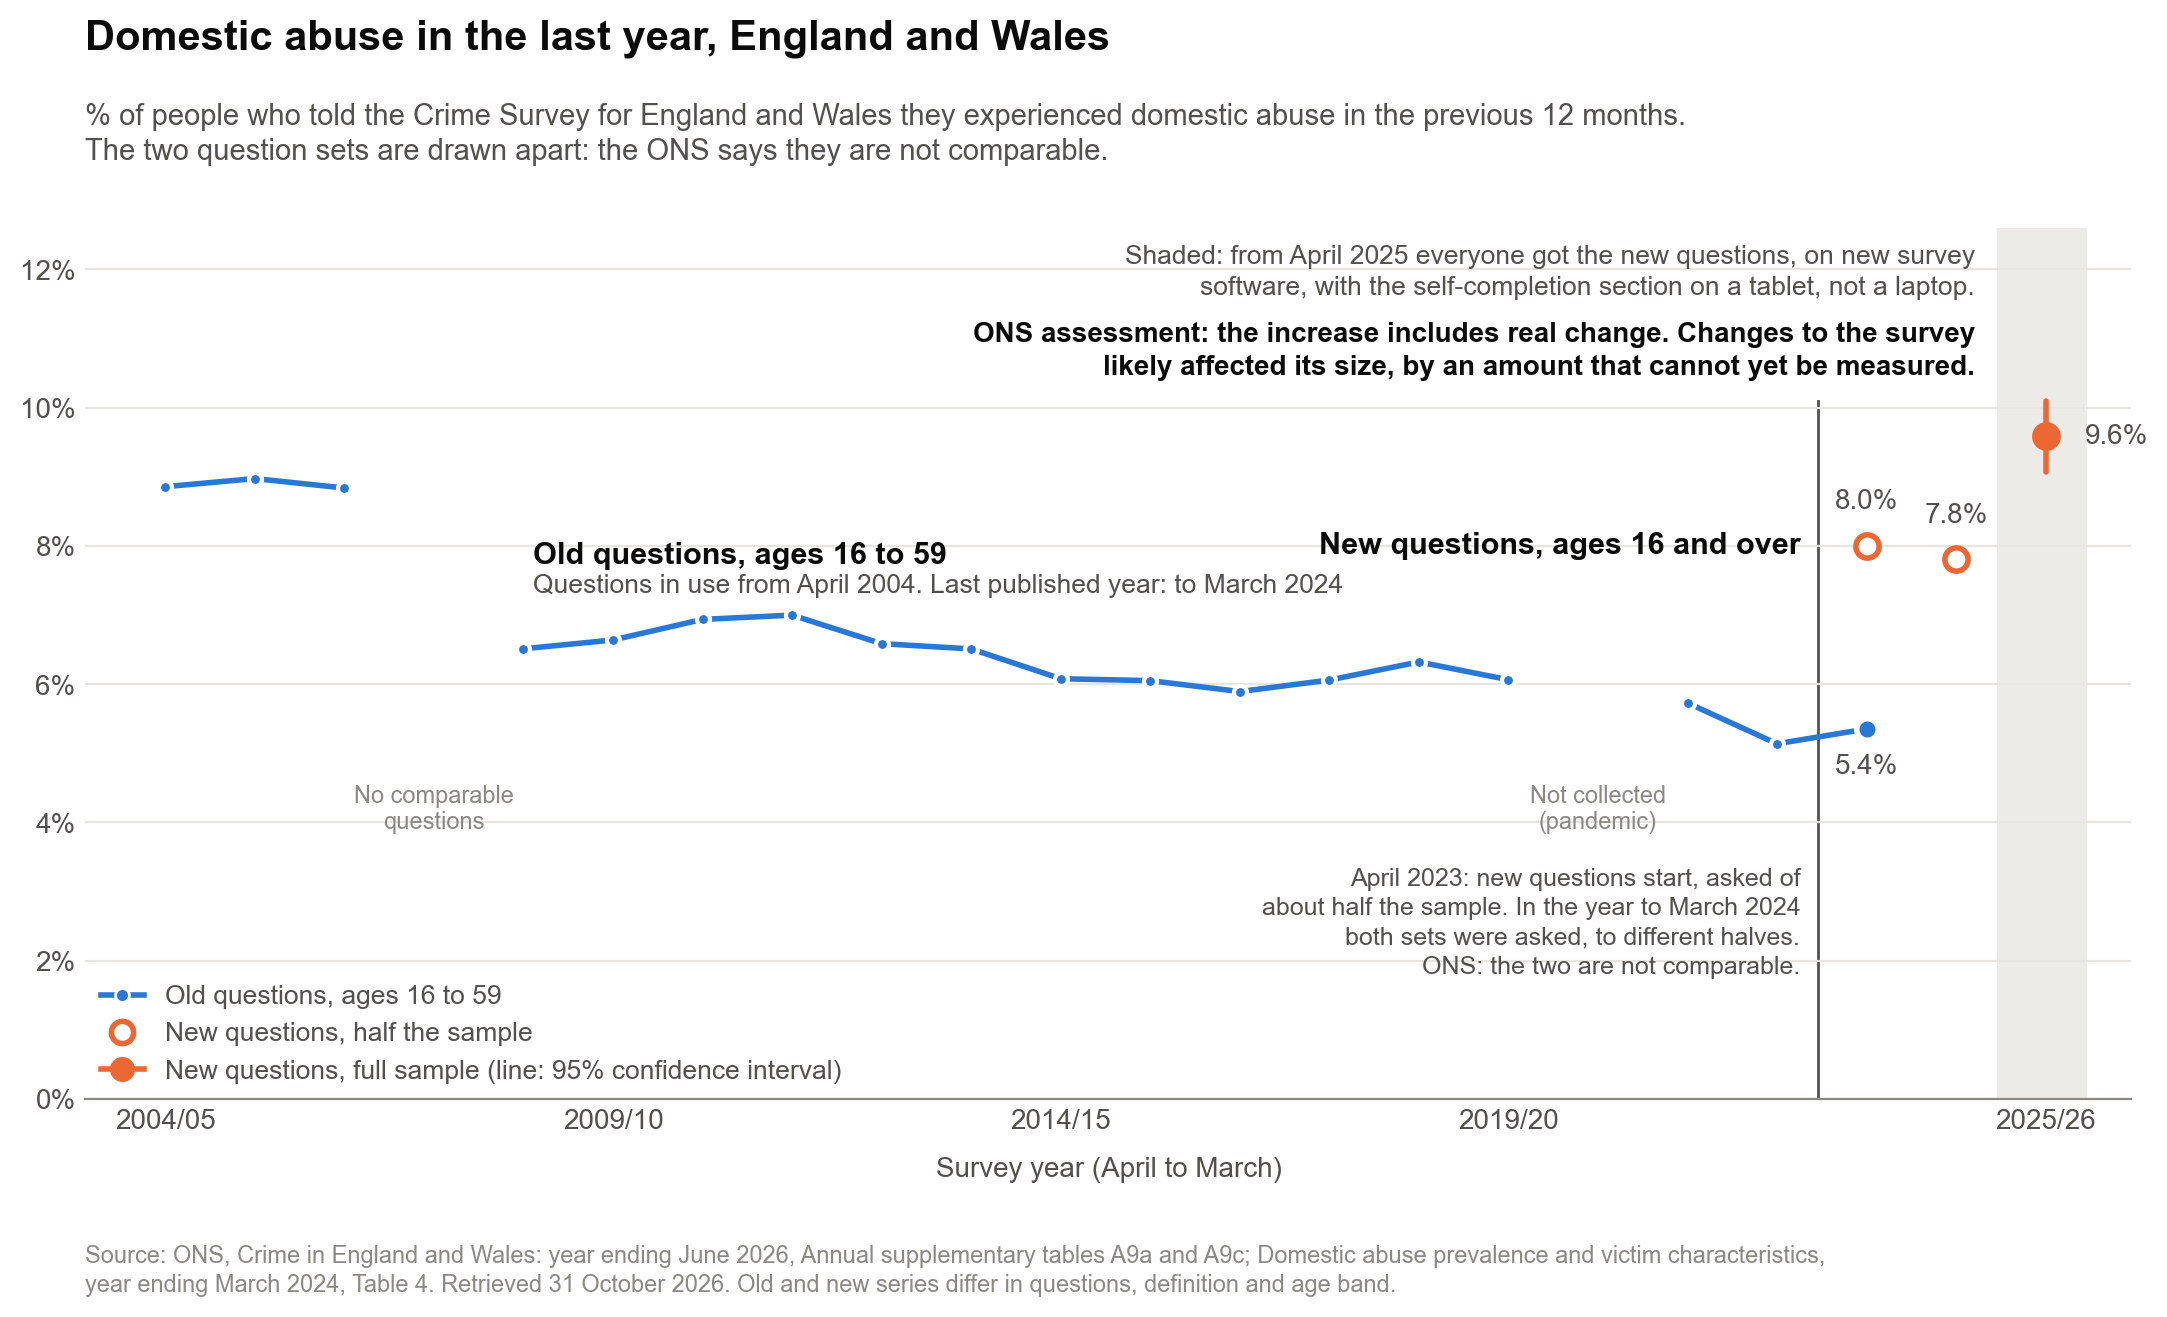

In [4]:
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8984"
OLD_C, NEW_C = "#2a78d6", "#eb6834"          # reference palette slots 1 and 2
BAND, RULE, GRID = "#ecebe7", "#52514e", "#e6e5e1"
APR_2023, APR_2025, MAR_2026 = 2023 + 3 / 12, 2025 + 3 / 12, 2026 + 3 / 12

plt.rcParams.update({"font.family": "Arial", "font.size": 11, "text.color": INK,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2})
fig, ax = plt.subplots(figsize=(11, 6.6), dpi=200)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# The shaded survey year: April 2025 to March 2026, collected under the new set-up.
ax.axvspan(APR_2025, MAR_2026, color=BAND, lw=0, zorder=0)
# April 2023: the new questions begin on half the sample. A plain rule, not dotted, so it can't read as a bridge.
# It stops below the text block at the top so it never runs through the ONS assessment.
ax.plot([APR_2023, APR_2023], [0, 10.1], color=RULE, lw=1, zorder=1)

# Old questions: a line in separate segments that stops dead at its last published year.
for seg in segments:
    xs, ys = zip(*seg)
    ax.plot(xs, ys, color=OLD_C, lw=2, solid_capstyle="round", zorder=3)
    ax.scatter(xs, ys, s=22, color=OLD_C, edgecolor="white", linewidth=1.5, zorder=4)
last = old.dropna(subset=["estimate_pct"]).iloc[-1]
ax.scatter([last.x], [last.estimate_pct], s=60, color=OLD_C, edgecolor="white", linewidth=2, zorder=5)

# New questions: unconnected points. Open = split sample (about half of respondents); filled = full sample.
for _, r in new.iterrows():
    full = r.sample_design == "full sample"
    if r.ci_published:
        ax.plot([r.x, r.x], [r.ci_lower_pct, r.ci_upper_pct], color=NEW_C, lw=2, solid_capstyle="round", zorder=5)
    ax.scatter([r.x], [r.estimate_pct], s=70, zorder=6, linewidth=2,
               color=NEW_C if full else "white", edgecolor=NEW_C)

# Values on the end points only: where the old series stops, and each new estimate.
ax.annotate(f"{last.estimate_pct:.1f}%", (last.x, last.estimate_pct), xytext=(0, -16), textcoords="offset points",
            ha="center", fontsize=10, color=INK_2)
for _, r in new.iterrows():
    dx = 14 if r.ci_published else 0
    dy = 0 if r.ci_published else 11
    ax.annotate(f"{r.estimate_pct:.1f}%", (r.x, r.estimate_pct), xytext=(dx, dy), textcoords="offset points",
                ha="left" if r.ci_published else "center", va="center" if r.ci_published else "bottom",
                fontsize=10, color=INK_2)

# Direct labels for the two series.
ax.text(2008.9, 7.75, "Old questions, ages 16 to 59", color=INK, fontsize=11, fontweight="bold")
ax.text(2008.9, 7.32, "Questions in use from April 2004. Last published year: to March 2024",
        color=INK_2, fontsize=9.5)
# Level with the first new-questions point but on the far side of the April 2023 rule, where there is room.
ax.text(APR_2023 - 0.2, 8.0, "New questions, ages 16 and over", color=INK, fontsize=11,
        fontweight="bold", ha="right", va="center")

# The two gaps inside the old series, named where they are.
ax.text(midpoint("2008-03"), 4.55, "No comparable\nquestions", ha="center", va="top", fontsize=8.5, color=INK_3)
ax.text(midpoint("2021-03"), 4.55, "Not collected\n(pandemic)", ha="center", va="top", fontsize=8.5, color=INK_3)

# April 2023 note, left of its rule.
ax.text(APR_2023 - 0.2, 3.35,
        "April 2023: new questions start, asked of\nabout half the sample. In the year to March 2024\n"
        "both sets were asked, to different halves.\nONS: the two are not comparable.",
        ha="right", va="top", fontsize=9, color=INK_2, linespacing=1.35)

# The shaded year and the ONS assessment, kept together so a screenshot keeps both.
ax.text(APR_2025 - 0.25, 12.35,
        "Shaded: from April 2025 everyone got the new questions, on new survey\n"
        "software, with the self-completion section on a tablet, not a laptop.",
        ha="right", va="top", fontsize=9.5, color=INK_2, linespacing=1.35)
ax.text(APR_2025 - 0.25, 11.25,
        "ONS assessment: the increase includes real change. Changes to the survey\n"
        "likely affected its size, by an amount that cannot yet be measured.",
        ha="right", va="top", fontsize=10, color=INK, fontweight="bold", linespacing=1.35)

# Axes: zero baseline, recessive grid, one y scale.
ax.set_ylim(0, 12.6)
ax.set_xlim(2003.9, 2026.75)
ax.set_yticks(range(0, 13, 2))
ax.set_yticklabels([f"{t}%" for t in range(0, 13, 2)])
ticks = ["2005-03", "2010-03", "2015-03", "2020-03", "2026-03"]
ax.set_xticks([midpoint(t) for t in ticks])
ax.set_xticklabels([f"{int(t[:4]) - 1}/{t[2:4]}" for t in ticks])
ax.set_xlabel("Survey year (April to March)", fontsize=10, labelpad=8)
ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
ax.tick_params(length=0, labelsize=10)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_3)

legend = [Line2D([0], [0], color=OLD_C, lw=2, marker="o", markersize=5, markeredgecolor="white",
                 label="Old questions, ages 16 to 59"),
          Line2D([0], [0], color="none", marker="o", markersize=8, markerfacecolor="white",
                 markeredgecolor=NEW_C, markeredgewidth=2, label="New questions, half the sample"),
          Line2D([0], [0], color=NEW_C, lw=2, marker="o", markersize=8, markerfacecolor=NEW_C,
                 markeredgecolor=NEW_C, label="New questions, full sample (line: 95% confidence interval)")]
ax.legend(handles=legend, loc="lower left", frameon=False, fontsize=9.5, labelcolor=INK_2, handlelength=1.6,
          borderaxespad=0.2)

fig.text(0.055, 0.965, "Domestic abuse in the last year, England and Wales", fontsize=15, fontweight="bold",
         color=INK, ha="left")
fig.text(0.055, 0.925, "% of people who told the Crime Survey for England and Wales they experienced domestic abuse "
         "in the previous 12 months.\nThe two question sets are drawn apart: the ONS says they are not comparable.",
         fontsize=10.5, color=INK_2, ha="left", va="top", linespacing=1.35)
fig.text(0.055, 0.02,
         "Source: ONS, Crime in England and Wales: year ending June 2026, Annual supplementary tables A9a and A9c; "
         "Domestic abuse prevalence and victim characteristics,\nyear ending March 2024, Table 4. Retrieved "
         "31 October 2026. Old and new series differ in questions, definition and age band.",
         fontsize=8.5, color=INK_3, ha="left", va="bottom", linespacing=1.35)
fig.subplots_adjust(left=0.055, right=0.985, top=0.83, bottom=0.17)

for ext in ("png", "svg"):
    fig.savefig(CHARTS / f"domestic_abuse_two_question_sets.{ext}", facecolor="white")
plt.show()

## Alt text, generated from the same numbers

In [5]:
o = old.dropna(subset=["estimate_pct"])
n26 = new[new.year_ending.eq("2026-03")].iloc[0]
n = new.set_index("year_ending").estimate_pct
alt = (
    "Chart of the share of people in England and Wales who reported domestic abuse in the previous 12 months. "
    f"A line shows the old survey questions, for ages 16 to 59, from {o.estimate_pct.iloc[0]:.1f}% in 2004/05 to "
    f"{o.estimate_pct.iloc[-1]:.1f}% in 2023/24, where it ends. It has gaps for 2007/08 (no comparable questions) "
    "and 2020/21 (not collected during the pandemic). Separate points, not joined to the line or to each other, "
    f"show the new questions for ages 16 and over: {n['2024-03']:.1f}% in 2023/24 and {n['2025-03']:.1f}% in "
    f"2024/25 from about half the sample, and {n26.estimate_pct:.1f}% in 2025/26 from the full sample "
    f"(95% confidence interval {n26.ci_lower_pct:.1f}% to {n26.ci_upper_pct:.1f}%). A vertical line marks April 2023, "
    "when the new questions began; the ONS says the two question sets are not comparable. The 2025/26 survey year is "
    "shaded: from April 2025 everyone got the new questions, on new survey software and a tablet. " + VERDICT
)
(CHARTS / "domestic_abuse_two_question_sets_alt.txt").write_text(alt + "\n")
print(alt)

Chart of the share of people in England and Wales who reported domestic abuse in the previous 12 months. A line shows the old survey questions, for ages 16 to 59, from 8.9% in 2004/05 to 5.4% in 2023/24, where it ends. It has gaps for 2007/08 (no comparable questions) and 2020/21 (not collected during the pandemic). Separate points, not joined to the line or to each other, show the new questions for ages 16 and over: 8.0% in 2023/24 and 7.8% in 2024/25 from about half the sample, and 9.6% in 2025/26 from the full sample (95% confidence interval 9.1% to 10.1%). A vertical line marks April 2023, when the new questions began; the ONS says the two question sets are not comparable. The 2025/26 survey year is shaded: from April 2025 everyone got the new questions, on new survey software and a tablet. ONS assessment: the increase includes real change. Changes to the survey likely affected its size, by an amount that cannot yet be measured.
